# Stock Price Prediction with an LSTM: can a network beat "tomorrow will be like today"?

**The question:** a stacked LSTM, a network built to learn from sequences, can be trained on a stock's past prices and will happily draw a line that follows the real price closely. That looks like prediction. But a line that hugs the price is exactly what you get by saying "tomorrow's price will be today's price". So the real questions are: *is the price predictable at all, does the network beat that one-line baseline, can it call the direction of the next move, and what happens when it forecasts a month ahead?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: is the price predictable at all?
6. The model
7. H2: does the LSTM beat "tomorrow = today"?
8. H3: can it call the direction?
9. H4: what about forecasting 30 days ahead?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab DL/stock-price-lstm/stock_price_lstm.ipynb`, or *Run All* in any Jupyter. The price history (about 100 KB, Tesla, 2016 to 2025) downloads itself on the first run from Yahoo Finance; no account or key is needed. It uses a GPU if present and takes about 5 minutes on one.

> **This is a teaching example about forecasting methods, not financial advice.**

## 1. 💡 The simple analogy

Imagine a **person stumbling home after a long night**. At each step they lurch left or right at random.

- The best guess of where they will be one step from now is **where they are now**: this is the **random walk**, and "tomorrow = today" is the **persistence** forecast.
- A model that draws a smooth line through their footsteps *looks* clever, but if every step is random it cannot beat that guess.
- What you *can* predict is **how wildly** they will lurch: after a big stagger, another big one is more likely. This is **volatility clustering**.
- A forecaster who learned the walker's path **only while they were near the pub** will be lost once the walker is blocks away, in places they never saw. That is what happens when a model trained on one range of prices is asked about prices far above it.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the window length and the training budget keeps the notebook reproducible and avoids "magic numbers". The date range is fixed, so the notebook gives the same answers on any day.

In [1]:
import json
import urllib.request
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import torch
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.proportion import proportion_confint
from statsmodels.tsa.stattools import acf, adfuller
from torch import nn

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
TICKER = "TSLA"
START, END = "2016-10-31", "2026-01-01"  # END is exclusive: the last day used is 2025-12-31
SEED = 365
WINDOW = 80  # trading days of history the network sees (the legacy value)
HORIZON = 30  # days ahead in the multi-step forecasts
N_SEEDS = 5
N_BOOTSTRAP = 2_000
EPOCHS = 60
BATCH = 64
LEARNING_RATE = 2e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load Tesla's daily closing prices (adjusted for stock splits) from 31 October 2016 to 31 December 2025, and split the days **in time order**: the first 60% for training, the next 20% for validation (picking the best training epoch) and the last 20% for the test. *Why:* with time series, shuffling the days lets the model peek at the future, so the test period must come strictly after the training period.

> **Problems in the legacy notebook this replaces:** it needed a Tiingo API key (placeholder in the code) and Colab; it scaled the prices using the **whole** history, test days included; it built the test windows separately, losing the first 80 days of context; it used the test set as validation data for 200 epochs; and it computed its RMSE between **scaled targets** (0 to 1) and **predictions in dollars**, so the "515" and "696" it reports are meaningless and the "underfitting" diagnosis built on them is wrong. It then fed predictions back to forecast 30 days ahead with no baseline to compare against.

In [2]:
def load_prices() -> pd.DataFrame:
    """Daily split-adjusted closing prices, downloaded once from Yahoo Finance and cached.

    The date range is fixed (``START`` to ``END``) so the notebook gives the same answers on any
    day. No account or API key is needed.

    Returns:
        A table indexed by date with columns ``close`` and ``volume``.

    Raises:
        ValueError: If the download is empty or has missing prices.
    """
    path = DATA_DIR / f"{TICKER.lower()}_daily.csv"
    if not path.exists():

        def stamp(day: str) -> int:
            return int(datetime.fromisoformat(day).replace(tzinfo=UTC).timestamp())

        url = (
            f"https://query1.finance.yahoo.com/v8/finance/chart/{TICKER}"
            f"?period1={stamp(START)}&period2={stamp(END)}&interval=1d&events=history"
        )
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request) as response:
            result = json.load(response)["chart"]["result"][0]
        frame = pd.DataFrame(
            {
                "close": result["indicators"]["adjclose"][0]["adjclose"],
                "volume": result["indicators"]["quote"][0]["volume"],
            },
            index=pd.to_datetime(result["timestamp"], unit="s").normalize(),
        )
        frame.index.name = "date"
        frame.to_csv(path)
    prices = pd.read_csv(path, index_col="date", parse_dates=True)
    if prices.empty or prices["close"].isna().any():
        raise ValueError("The price file is empty or has missing prices")
    return prices


prices = load_prices()
close = prices["close"].to_numpy()
dates = prices.index
log_returns = np.diff(np.log(close))
n_days = len(close)
print(f"{n_days:,} trading days of {TICKER}, {dates[0].date()} to {dates[-1].date()}")
print(
    f"Adjusted close: first ${close[0]:.2f}, last ${close[-1]:.2f}, minimum ${close.min():.2f}, "
    f"maximum ${close.max():.2f}"
)
print(
    f"Daily log returns: mean {log_returns.mean() * 100:.3f}%, sd {log_returns.std() * 100:.2f}%, "
    f"worst {log_returns.min() * 100:.1f}%, best {log_returns.max() * 100:.1f}%"
)
print(f"Share of days the price went up: {(log_returns > 0).mean():.1%}")

cut_train, cut_val = int(0.6 * n_days), int(0.8 * n_days)
periods = {"train": (0, cut_train), "validation": (cut_train, cut_val), "test": (cut_val, n_days)}
for name, (a, b) in periods.items():
    seg = close[a:b]
    print(
        f"{name:10s}: {dates[a].date()} to {dates[b - 1].date()} ({b - a:,} days), "
        f"price ${seg.min():.2f} to ${seg.max():.2f}"
    )
train_max = close[:cut_train].max()
share_above = (close[cut_val:] > train_max).mean()
print(
    f"\nShare of test days priced above anything seen in training (> ${train_max:.2f}): "
    f"{share_above:.1%}"
)

2,305 trading days of TSLA, 2016-10-31 to 2025-12-31
Adjusted close: first $13.18, last $449.72, minimum $11.93, maximum $489.88
Daily log returns: mean 0.153%, sd 3.81%, worst -23.7%, best 20.4%
Share of days the price went up: 52.0%
train     : 2016-10-31 to 2022-04-28 (1,383 days), price $11.93 to $409.97
validation: 2022-04-29 to 2024-02-29 (461 days), price $108.10 to $317.54
test      : 2024-03-01 to 2025-12-31 (461 days), price $142.05 to $489.88

Share of test days priced above anything seen in training (> $409.97): 19.5%


**How to read this:**

- **2,305 trading days** from 2016-10-31 to 2025-12-31. The split-adjusted price runs from **$13.18** to **$449.72** at the end (with a low of $11.93 and a high of $489.88). (The raw prices in the legacy notebook, $197 to $1,114, are not adjusted for the later stock splits; returns are unaffected.)
- **Daily log returns** average **+0.153%** with a standard deviation of **3.81%**; the worst day was **-23.7%** and the best **+20.4%**. The price rose on **52.0%** of days.
- **The three periods:** training **1,383 days** (to 2022-04-28, prices $11.93 to $409.97), validation **461 days** (2022-04-29 to 2024-02-29, $108.10 to $317.54) and test **461 days** (2024-03-01 to 2025-12-31, $142.05 to $489.88).
- **A warning sign:** **19.5% of the test days** are priced above anything the model saw in training (above **$409.97**). A model that learns *levels* is being asked about places it has never been.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Is the price predictable from its own past? | The price is a random walk: returns have no memory | Returns (or their size) have memory | Augmented Dickey-Fuller on prices and returns; Ljung-Box and autocorrelation of returns and of squared returns |
| H2 | Does an LSTM predict tomorrow's price better than "tomorrow = today"? | Equal squared error | Smaller squared error | RMSE over 5 seeds; Diebold-Mariano test with Newey-West errors |
| H3 | Can it call the direction (up or down) of the next day? | Accuracy = 50% (or the share of up days) | Higher | Binomial tests, Wilson CI, rank correlation of predicted and actual returns |
| H4 | Is a 30-day recursive forecast better than "stay where you are"? | Equal error | Lower error | Wilcoxon over 87 start dates |

*Why these tests?* Prices drift, so ordinary tests on prices are misleading: we test **returns**, which are stationary. The Diebold-Mariano test is the standard way to compare two forecasts of the *same* days, and its Newey-West correction allows for the errors of neighbouring days being related. The Wilcoxon test is used where the errors are skewed.

## 5. H1: is the price predictable at all?

*What:* three checks before any model. (1) The **Augmented Dickey-Fuller** test on log prices and on returns: if the price is a random walk, the test cannot reject that it has a "unit root", while returns should clearly be stationary. (2) The **Ljung-Box test** for correlation between a day's return and those of the previous days (lags up to 20), and the autocorrelations themselves. (3) The same tests on **squared returns**, which measure the *size* of moves. *Why:* if returns have no memory, no model can predict the direction of tomorrow's move from past prices, whatever its architecture.

In [3]:
adf_price = adfuller(np.log(close), autolag="AIC", result_object=False)
adf_ret = adfuller(log_returns, autolag="AIC", result_object=False)
print(
    f"ADF test on log prices:  statistic {adf_price[0]:.2f}, p = {adf_price[1]:.3f} "
    "(H0: the series is a random walk with drift)"
)
print(f"ADF test on log returns: statistic {adf_ret[0]:.2f}, p = {fmt_p(adf_ret[1])}")

lb_ret = acorr_ljungbox(log_returns, lags=[1, 5, 10, 20])
lb_sq = acorr_ljungbox(log_returns**2, lags=[1, 5, 10, 20])
print("\nLjung-Box test of 'no autocorrelation' (p-values):")
table = pd.DataFrame({"returns": lb_ret["lb_pvalue"], "squared returns": lb_sq["lb_pvalue"]})
table.index = [f"lag {lag}" for lag in (1, 5, 10, 20)]
print(table.map(fmt_p).to_string())
rho = acf(log_returns, nlags=10)
band = 1.96 / np.sqrt(len(log_returns))
print(
    f"\nAutocorrelation of returns at lags 1 to 10 (95% noise band +-{band:.3f}): "
    + ", ".join(f"{r:+.3f}" for r in rho[1:])
)
rho_sq = acf(log_returns**2, nlags=10)
print(
    "Autocorrelation of squared returns at lags 1 to 10: "
    + ", ".join(f"{r:+.3f}" for r in rho_sq[1:])
)

ADF test on log prices:  statistic -1.03, p = 0.741 (H0: the series is a random walk with drift)
ADF test on log returns: statistic -33.16, p = < 1e-300

Ljung-Box test of 'no autocorrelation' (p-values):
        returns squared returns
lag 1   4.0e-01         1.8e-08
lag 5   4.2e-01         5.1e-30
lag 10  3.8e-01         2.7e-34
lag 20  3.1e-02         4.1e-53

Autocorrelation of returns at lags 1 to 10 (95% noise band +-0.041): -0.018, +0.031, +0.015, +0.001, -0.026, +0.009, +0.034, +0.010, +0.034, -0.001
Autocorrelation of squared returns at lags 1 to 10: +0.117, +0.146, +0.110, +0.099, +0.083, +0.047, +0.056, +0.049, +0.069, +0.059


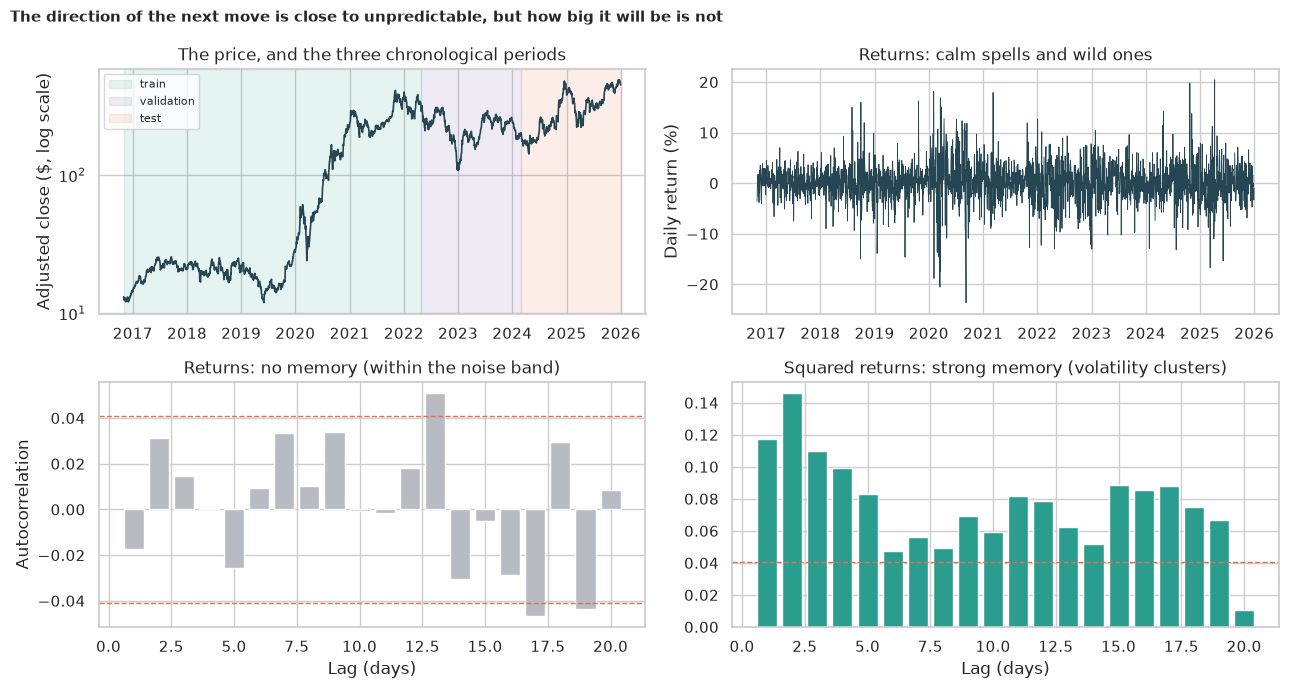

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes[0, 0].plot(dates, close, color=NAVY, lw=1.2)
for name, (a, b) in periods.items():
    axes[0, 0].axvspan(
        dates[a],
        dates[b - 1],
        alpha=0.12,
        color={"train": TEAL, "validation": PURPLE, "test": ORANGE}[name],
        label=name,
    )
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel("Adjusted close ($, log scale)")
axes[0, 0].set_title("The price, and the three chronological periods")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(dates[1:], log_returns * 100, color=NAVY, lw=0.6)
axes[0, 1].set_ylabel("Daily return (%)")
axes[0, 1].set_title("Returns: calm spells and wild ones")
lags = np.arange(1, 21)
axes[1, 0].bar(lags, acf(log_returns, nlags=20)[1:], color=GREY)
axes[1, 0].axhline(band, color=ORANGE, ls="--", lw=1)
axes[1, 0].axhline(-band, color=ORANGE, ls="--", lw=1)
axes[1, 0].set_xlabel("Lag (days)")
axes[1, 0].set_ylabel("Autocorrelation")
axes[1, 0].set_title("Returns: no memory (within the noise band)")
axes[1, 1].bar(lags, acf(log_returns**2, nlags=20)[1:], color=TEAL)
axes[1, 1].axhline(band, color=ORANGE, ls="--", lw=1)
axes[1, 1].set_xlabel("Lag (days)")
axes[1, 1].set_title("Squared returns: strong memory (volatility clusters)")
fig.suptitle(
    "The direction of the next move is close to unpredictable, but how big it will be is not",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_returns.png", dpi=150)
plt.show()

**How to read this:**

- **The price behaves like a random walk with drift:** the ADF test on log prices gives **p = 0.741** (we cannot reject a unit root), while on returns **p < 1e-300** (stationary). The right thing to model is returns, not prices.
- **Returns have almost no memory:** the Ljung-Box p-values are **0.40** (lag 1), **0.42** (lag 5) and **0.38** (lag 10). At lag 20 it is **0.031**, which after correcting for four tests (0.031 x 4 = 0.12) is not significant. The autocorrelations at lags 1 to 10 all lie inside the ±**0.041** noise band (the largest is +0.034). **We fail to reject H₀** for the direction of returns.
- **But the size of moves has strong memory:** for squared returns the p-values range from **1.8e-8** (lag 1) to **4.1e-53** (lag 20), and the autocorrelations are **+0.117, +0.146, +0.110...** at lags 1 to 3. Big days follow big days: **volatility clusters**. **We reject H₀** for the size of the moves.
- So the next day's direction is close to a coin toss, while its likely size is partly predictable. A forecaster can say "tomorrow could be wild", not "tomorrow it goes up".

## 6. The model

*What:* a **stacked LSTM** (three layers of 64 units, as in the legacy notebook) that reads the previous **80 trading days** and predicts the next day. We train it in two ways, and compare both with the **persistence** baseline:

1. **On price levels:** the input is the price scaled to 0 to 1 using the **training days only**, and the output is tomorrow's scaled price. This is the legacy approach, with the data leak removed.
2. **On daily returns:** the input is the past 80 days of returns (standardised using training days only) and the output is tomorrow's return; the predicted price is today's price times e raised to the predicted return. This is the approach H1 recommends.

Both use Adam (learning rate 0.002, batches of 64, up to 60 epochs) and keep the weights from the **best validation epoch**. The test days are never used for any choice. Each is trained **5 times** with different seeds.

In [5]:
class StackedLSTM(nn.Module):
    """Three stacked LSTM layers (64 units each, as in the legacy notebook) and a linear output."""

    def __init__(self) -> None:
        super().__init__()
        self.lstm = nn.LSTM(1, 64, num_layers=3, batch_first=True)
        self.head = nn.Linear(64, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Predicts the next value from a window of shape (batch, WINDOW, 1)."""
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(1)


def make_windows(series: np.ndarray, start: int, stop: int) -> tuple[np.ndarray, np.ndarray]:
    """Cuts a series into (previous WINDOW values -> next value) examples.

    Only targets with index in ``[start, stop)`` are used and every window may look back into
    earlier periods (that is information the forecaster really has), never forward.

    Args:
        series: The series to cut up.
        start: First target index to include.
        stop: One past the last target index to include.

    Returns:
        Windows of shape (n, WINDOW) and the next values, shape (n,).
    """
    first = max(start, WINDOW)
    x = np.stack([series[t - WINDOW : t] for t in range(first, stop)])
    return x, series[first:stop]


def train_lstm(series: np.ndarray, train_stop: int, val_stop: int, seed: int) -> nn.Module:
    """Trains a stacked LSTM and keeps the weights from the best validation epoch.

    Args:
        series: The (already scaled) series the network learns from.
        train_stop: Targets before this index are training examples.
        val_stop: Targets from ``train_stop`` up to here are validation examples.
        seed: Seed for the weights and batch order.

    Returns:
        The trained network in evaluation mode.
    """
    torch.manual_seed(seed)
    model = StackedLSTM().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    xt, yt = (
        torch.tensor(a, dtype=torch.float32, device=DEVICE)
        for a in make_windows(series, 0, train_stop)
    )
    xv, yv = (
        torch.tensor(a, dtype=torch.float32, device=DEVICE)
        for a in make_windows(series, train_stop, val_stop)
    )
    xt, xv = xt.unsqueeze(-1), xv.unsqueeze(-1)
    best_state, best_loss = None, float("inf")
    for _ in range(EPOCHS):
        model.train()
        order = torch.randperm(len(xt), device=DEVICE)
        for start in range(0, len(xt), BATCH):
            pick = order[start : start + BATCH]
            loss = nn.functional.mse_loss(model(xt[pick]), yt[pick])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = nn.functional.mse_loss(model(xv), yv).item()
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model.eval()


def predict_series(model: nn.Module, series: np.ndarray, targets: np.ndarray) -> np.ndarray:
    """One-step-ahead predictions for the given target days.

    Args:
        model: A trained network.
        series: The scaled series the network reads.
        targets: Indices of the days to predict (each uses the ``WINDOW`` days before it).

    Returns:
        Predictions on the same (scaled) scale as ``series``.
    """
    x = np.stack([series[t - WINDOW : t] for t in targets])
    with torch.no_grad():
        tensor = torch.tensor(x, dtype=torch.float32, device=DEVICE).unsqueeze(-1)
        return model(tensor).cpu().numpy()

## 7. H2: does the LSTM beat "tomorrow = today"?

*What:* every test day, each model predicts the closing price from the 80 days before it. We report the **RMSE** in dollars, and a "skill score" = 1 - (model's squared error / persistence's squared error): positive means better than persistence, negative worse. The **Diebold-Mariano test** compares the squared errors of the two forecasts day by day (seed 0), with an adjustment for neighbouring days being related. *Why persistence?* It costs nothing and needs no model: any real forecaster must beat it.

In [6]:
lo, hi = close[:cut_train].min(), close[:cut_train].max()  # scale from training days only
level_series = (close - lo) / (hi - lo)
ret_mu, ret_sd = log_returns[: cut_train - 1].mean(), log_returns[: cut_train - 1].std()
ret_series = np.concatenate([[0.0], (log_returns - ret_mu) / ret_sd])  # day t's own return
test_days = np.arange(cut_val, n_days)
actual = close[test_days]
persistence = close[test_days - 1]  # "tomorrow will be like today"

level_models = [train_lstm(level_series, cut_train, cut_val, s) for s in range(N_SEEDS)]
ret_models = [train_lstm(ret_series, cut_train, cut_val, s) for s in range(N_SEEDS)]
level_preds = [predict_series(m, level_series, test_days) * (hi - lo) + lo for m in level_models]
ret_preds = [
    close[test_days - 1] * np.exp(predict_series(m, ret_series, test_days) * ret_sd + ret_mu)
    for m in ret_models
]


def rmse(pred: np.ndarray) -> float:
    """Root-mean-squared error in dollars against the actual closing prices."""
    return float(np.sqrt(np.mean((pred - actual) ** 2)))


rmse_persist = rmse(persistence)
rows = [{"model": "Persistence (tomorrow = today)", "rmse": rmse_persist, "skill": 0.0}]
for name, preds in [("LSTM on price levels", level_preds), ("LSTM on daily returns", ret_preds)]:
    values = np.array([rmse(p) for p in preds])
    skill = 1 - (values / rmse_persist) ** 2 + 0.0  # + 0.0 turns a tiny -0.000 into 0.000
    rows.append(
        {
            "model": f"{name} (mean of {N_SEEDS} seeds)",
            "rmse": values.mean(),
            "skill": skill.mean(),
            "rmse_min": values.min(),
            "rmse_max": values.max(),
        }
    )
summary = pd.DataFrame(rows).set_index("model")
print(
    f"Test period: {dates[cut_val].date()} to {dates[-1].date()}, {len(test_days)} days; "
    f"actual price ${actual.min():.0f} to ${actual.max():.0f}"
)
print(summary.round(3).to_string())
print("(skill = 1 - MSE / MSE of persistence: above 0 beats persistence, below 0 is worse)")


def diebold_mariano(err_a: np.ndarray, err_b: np.ndarray, lags: int = 5) -> tuple[float, float]:
    """Diebold-Mariano test that forecast A is as accurate as forecast B (squared error).

    The loss gap of two forecasts of the same days is correlated from day to day, so the
    standard error uses a Newey-West (HAC) correction.

    Args:
        err_a: Errors of forecast A.
        err_b: Errors of forecast B.
        lags: Number of lags for the HAC correction.

    Returns:
        The mean loss gap (A minus B) and its two-sided p-value.
    """
    gap = err_a**2 - err_b**2
    fit = sm.OLS(gap, np.ones(len(gap))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(gap.mean()), float(fit.pvalues[0])


print("\nDiebold-Mariano tests against persistence (seed 0):")
for name, preds in [("LSTM on price levels", level_preds), ("LSTM on daily returns", ret_preds)]:
    gap, p = diebold_mariano(preds[0] - actual, persistence - actual)
    print(f"  {name}: mean squared-error gap {gap:+,.1f} ($^2), p = {fmt_p(p)}")
below = np.mean([(level_preds[0][i] < actual[i]) for i in range(len(actual))])
print(f"\nLSTM on levels under-predicts on {below:.0%} of test days")

Test period: 2024-03-01 to 2025-12-31, 461 days; actual price $142 to $490
                                           rmse  skill  rmse_min  rmse_max
model                                                                     
Persistence (tomorrow = today)           11.899  0.000       NaN       NaN
LSTM on price levels (mean of 5 seeds)   14.611 -0.518    13.526    16.724
LSTM on daily returns (mean of 5 seeds)  11.900 -0.000    11.857    11.953
(skill = 1 - MSE / MSE of persistence: above 0 beats persistence, below 0 is worse)

Diebold-Mariano tests against persistence (seed 0):
  LSTM on price levels: mean squared-error gap +91.4 ($^2), p = 5.6e-08
  LSTM on daily returns: mean squared-error gap +0.3 ($^2), p = 8.4e-01

LSTM on levels under-predicts on 60% of test days


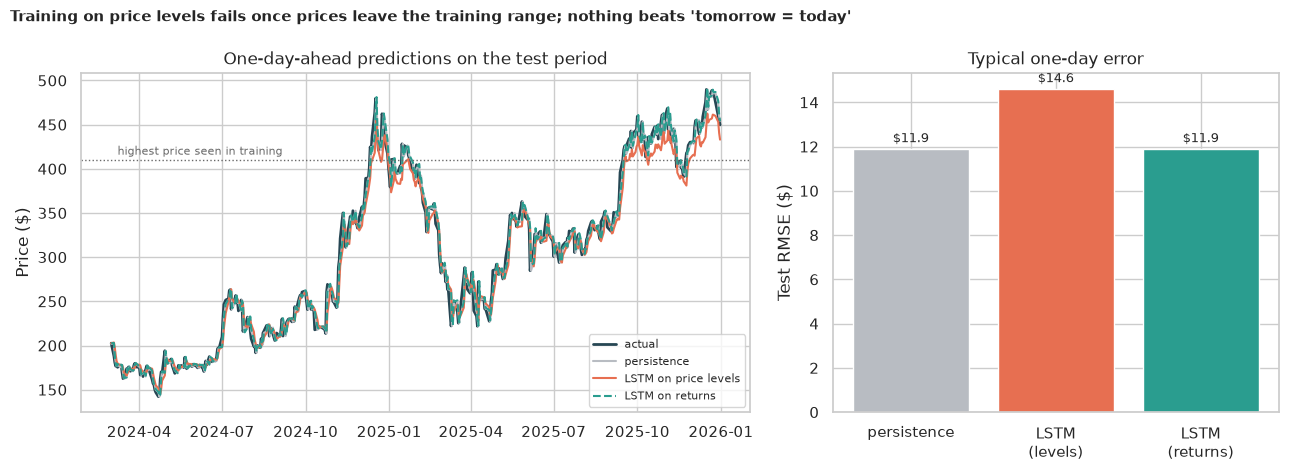

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].plot(dates[test_days], actual, color=NAVY, lw=2, label="actual")
axes[0].plot(dates[test_days], persistence, color=GREY, lw=1.5, label="persistence")
axes[0].plot(dates[test_days], level_preds[0], color=ORANGE, lw=1.5, label="LSTM on price levels")
axes[0].plot(dates[test_days], ret_preds[0], color=TEAL, lw=1.5, ls="--", label="LSTM on returns")
axes[0].axhline(train_max, color="dimgray", ls=":", lw=1)
axes[0].text(
    dates[test_days][5],
    train_max + 6,
    "highest price seen in training",
    fontsize=8,
    color="dimgray",
)
axes[0].set_ylabel("Price ($)")
axes[0].set_title("One-day-ahead predictions on the test period")
axes[0].legend(fontsize=8, loc="lower right")
labels_ = ["persistence", "LSTM\n(levels)", "LSTM\n(returns)"]
bars = [rmse_persist, summary.iloc[1]["rmse"], summary.iloc[2]["rmse"]]
axes[1].bar(labels_, bars, color=[GREY, ORANGE, TEAL])
for i, v in enumerate(bars):
    axes[1].text(i, v + 0.3, f"${v:.1f}", ha="center", fontsize=9)
axes[1].set_ylabel("Test RMSE ($)")
axes[1].set_title("Typical one-day error")
fig.suptitle(
    "Training on price levels fails once prices leave the training range; "
    "nothing beats 'tomorrow = today'",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_predictions.png", dpi=150)
plt.show()

**How to read this:**

- **Persistence is the bar:** its test RMSE is **$11.90** (the test prices run from $142 to $490).
- **The LSTM on price levels is worse:** RMSE **$14.61** (seeds range **$13.53 to $16.72**), a skill of **-0.52**: about 52% more squared error. The Diebold-Mariano test gives a mean squared-error gap of **+91.4** dollars squared, **p = 5.6e-8**. **We reject H₀**, in the wrong direction.
- **The LSTM on returns ties with persistence:** RMSE **$11.90** (seeds **$11.86 to $11.95**), skill **0.000**, Diebold-Mariano gap **+0.3**, **p = 0.84**. **We fail to reject H₀:** it is indistinguishable from "tomorrow = today". Its predicted returns are all close to the average daily drift, so its price forecast is essentially yesterday's price.
- **Why levels fail:** 19.5% of test days are above anything seen in training, and the model **under-predicts on 60% of test days**. In the plot the orange line sags below the actual price at the highs, and cannot follow it up.
- **The legacy RMSE is not comparable** with these numbers (it mixed scales); it should not be used to judge anything.

## 8. H3: can it call the direction?

*What:* for each test day we ask the models a simpler question than "what price?": will the price **rise or fall**? We compare the share of days the direction is right with two benchmarks: a **fair coin** (50%) and **always guessing the more common direction**. We use a binomial test, a Wilson confidence interval, and the **rank correlation** between predicted and actual returns. *Why:* a trader needs the direction more than the price, and accuracy in direction is easy to inflate when the market mostly goes one way.

In [8]:
up_actual = np.diff(np.log(close))[test_days - 1] > 0  # did the price rise on test day t?
up_share = up_actual.mean()
n_test = len(up_actual)
rows = []
for name, preds in [("LSTM on price levels", level_preds), ("LSTM on daily returns", ret_preds)]:
    for seed in range(N_SEEDS):
        predicted_up = preds[seed] > persistence
        hits = int((predicted_up == up_actual).sum())
        rows.append(
            {
                "model": name,
                "seed": seed,
                "accuracy": hits / n_test,
                "share predicted up": predicted_up.mean(),
            }
        )
direction = pd.DataFrame(rows)
print(
    f"Test days: {n_test}; the price rose on {up_share:.1%} of them "
    f"(always guessing 'up' scores {max(up_share, 1 - up_share):.1%})"
)
print(
    direction.groupby("model")[["accuracy", "share predicted up"]]
    .agg(["mean", "min", "max"])
    .round(3)
    .to_string()
)
best_hits = int(
    round(direction[direction["model"] == "LSTM on daily returns"]["accuracy"].mean() * n_test)
)
test_vs_coin = stats.binomtest(best_hits, n_test, 0.5)
low, high = proportion_confint(best_hits, n_test, method="wilson")
test_vs_up = stats.binomtest(best_hits, n_test, max(up_share, 1 - up_share))
print(
    f"\nLSTM on returns, average accuracy {best_hits / n_test:.1%} (95% Wilson CI {low:.1%} to "
    f"{high:.1%}); against a fair coin: p = {test_vs_coin.pvalue:.3f}; against always guessing "
    f"the more common direction: p = {test_vs_up.pvalue:.3f}"
)
pred_ret = [(np.log(p) - np.log(close[test_days - 1])) for p in ret_preds]
corr = [stats.spearmanr(pr, log_returns[test_days - 1]).statistic for pr in pred_ret]
print(
    f"Rank correlation between predicted and actual next-day return: "
    f"{np.mean(corr):+.3f} on average (range {min(corr):+.3f} to {max(corr):+.3f})"
)

Test days: 461; the price rose on 50.8% of them (always guessing 'up' scores 50.8%)
                      accuracy               share predicted up              
                          mean    min    max               mean    min    max
model                                                                        
LSTM on daily returns    0.527  0.503  0.551              0.751  0.453  1.000
LSTM on price levels     0.509  0.503  0.516              0.267  0.204  0.347

LSTM on returns, average accuracy 52.7% (95% Wilson CI 48.2% to 57.2%); against a fair coin: p = 0.264; against always guessing the more common direction: p = 0.428
Rank correlation between predicted and actual next-day return: +0.064 on average (range -0.016 to +0.102)


**How to read this:**

- **The price rose on 50.8% of the 461 test days**, so always guessing "up" would score **50.8%**.
- **The LSTM on returns gets 52.7% right on average** (95% Wilson CI **48.2% to 57.2%**; individual seeds **50.3% to 55.1%**). Against a fair coin the p-value is **0.264**, and against always guessing the more common direction **0.428**. **We fail to reject H₀.**
- **It mostly just guesses "up":** on average it predicts a rise on **75%** of days (from **45% to 100%** depending on the seed), and the market rose on about half of them, so most of its "skill" is the market's own drift. The levels model reaches **50.9%** (50.3% to 51.6%) while predicting "up" on only 27% of days.
- **The predicted and actual returns are barely related:** the rank correlation is **+0.064** on average (range **-0.016 to +0.102**).
- A strategy built on these predictions would not be expected to make money, and a few percentage points of luck over 461 days is well within the noise.

## 9. H4: what about forecasting 30 days ahead?

*What:* the legacy notebook predicted the next 30 days by feeding each prediction back in as the next input (a **recursive forecast**). We do the same from **87 start dates** spread over the test period (every fifth day) and measure the average absolute error as a percentage of the true price at each horizon, for the levels model, the returns model and the persistence forecast (the price stays at today's value). We compare errors at 30 days with Wilcoxon signed-rank tests, paired by start date.

In [9]:
def recursive_forecast(model: nn.Module, series: np.ndarray, start: int, steps: int) -> np.ndarray:
    """Forecasts ``steps`` days ahead by feeding each prediction back in as the next input.

    Args:
        model: A trained network.
        series: The scaled series (only values before ``start`` are used).
        start: First day to forecast.
        steps: Number of days to forecast.

    Returns:
        The forecasts on the scale of ``series``.
    """
    window = list(series[start - WINDOW : start])
    out = []
    for _ in range(steps):
        x = torch.tensor(np.array(window[-WINDOW:]), dtype=torch.float32, device=DEVICE)
        with torch.no_grad():
            nxt = float(model(x.view(1, WINDOW, 1)))
        out.append(nxt)
        window.append(nxt)
    return np.array(out)


starts = np.arange(cut_val, n_days - HORIZON, 5)
errors = {"persistence": [], "LSTM on price levels": [], "LSTM on daily returns": []}
for s in starts:
    truth = close[s : s + HORIZON]
    errors["persistence"].append(np.abs(close[s - 1] - truth) / truth)
    f_level = recursive_forecast(level_models[0], level_series, s, HORIZON) * (hi - lo) + lo
    errors["LSTM on price levels"].append(np.abs(f_level - truth) / truth)
    f_ret = recursive_forecast(ret_models[0], ret_series, s, HORIZON) * ret_sd + ret_mu
    f_ret = close[s - 1] * np.exp(np.cumsum(f_ret))
    errors["LSTM on daily returns"].append(np.abs(f_ret - truth) / truth)
errors = {k: np.array(v) * 100 for k, v in errors.items()}
horizons = [1, 5, 10, 20, 30]
table = pd.DataFrame(
    {k: [v[:, h - 1].mean() for h in horizons] for k, v in errors.items()},
    index=[f"{h} days" for h in horizons],
)
print(
    f"Average absolute error (% of the price) of recursive forecasts from {len(starts)} "
    "start dates in the test period:"
)
print(table.round(2).to_string())
for k in ("LSTM on price levels", "LSTM on daily returns"):
    diff = errors[k][:, HORIZON - 1] - errors["persistence"][:, HORIZON - 1]
    w = stats.wilcoxon(diff)
    print(
        f"  {HORIZON}-day horizon, {k} minus persistence: {diff.mean():+.2f} points "
        f"(worse in {(diff > 0).mean():.0%} of start dates), Wilcoxon p = {fmt_p(w.pvalue)}"
    )

Average absolute error (% of the price) of recursive forecasts from 87 start dates in the test period:
         persistence  LSTM on price levels  LSTM on daily returns
1 days          3.17                  4.20                   3.15
5 days          6.61                  8.03                   6.72
10 days         8.71                 11.80                   8.89
20 days        12.92                 16.17                  13.06
30 days        16.58                 18.86                  16.47
  30-day horizon, LSTM on price levels minus persistence: +2.28 points (worse in 60% of start dates), Wilcoxon p = 3.9e-02
  30-day horizon, LSTM on daily returns minus persistence: -0.11 points (worse in 39% of start dates), Wilcoxon p = 3.8e-01


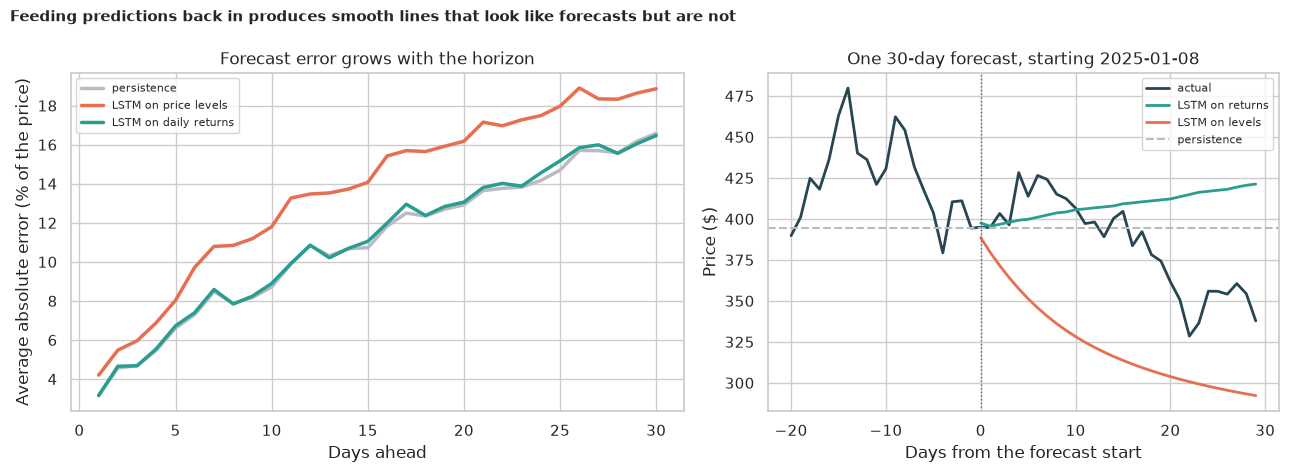

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
for name, color in zip(errors, [GREY, ORANGE, TEAL], strict=True):
    axes[0].plot(
        np.arange(1, HORIZON + 1), errors[name].mean(axis=0), color=color, lw=2.5, label=name
    )
axes[0].set_xlabel("Days ahead")
axes[0].set_ylabel("Average absolute error (% of the price)")
axes[0].set_title("Forecast error grows with the horizon")
axes[0].legend(fontsize=8)
example = starts[len(starts) // 2]
truth = close[example - 20 : example + HORIZON]
axes[1].plot(np.arange(-20, HORIZON), truth, color=NAVY, lw=2, label="actual")
f_ret = recursive_forecast(ret_models[0], ret_series, example, HORIZON) * ret_sd + ret_mu
axes[1].plot(
    np.arange(HORIZON),
    close[example - 1] * np.exp(np.cumsum(f_ret)),
    color=TEAL,
    lw=2,
    label="LSTM on returns",
)
f_level = recursive_forecast(level_models[0], level_series, example, HORIZON) * (hi - lo) + lo
axes[1].plot(np.arange(HORIZON), f_level, color=ORANGE, lw=2, label="LSTM on levels")
axes[1].axhline(close[example - 1], color=GREY, lw=1.5, ls="--", label="persistence")
axes[1].axvline(0, color="dimgray", lw=1, ls=":")
axes[1].set_xlabel("Days from the forecast start")
axes[1].set_ylabel("Price ($)")
axes[1].set_title(f"One 30-day forecast, starting {dates[example].date()}")
axes[1].legend(fontsize=8)
fig.suptitle(
    "Feeding predictions back in produces smooth lines that look like forecasts but are not",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_forecast_horizon.png", dpi=150)
plt.show()

**How to read this:**

- **Everyone's error grows quickly with the horizon:** persistence is off by **3.2%** after 1 day, **6.6%** after 5, **8.7%** after 10, **12.9%** after 20 and **16.6%** after 30 days.
- **The levels model is worse at every horizon:** **4.2%, 8.0%, 11.8%, 16.2% and 18.9%**. At 30 days it is **2.28 points** worse than persistence and worse on **60%** of start dates (Wilcoxon p = 0.039). **We reject H₀**, in the wrong direction.
- **The returns model matches persistence:** **3.15%, 6.7%, 8.9%, 13.1% and 16.5%**; at 30 days it is **-0.11 points** from persistence (better on 61% of start dates; p = 0.38). **We fail to reject H₀.**
- **The 30-day forecast looks plausible but carries no information:** in the example plot the returns model draws a gentle rise (just the average drift) while the price fell, and the levels model draws a smooth decline back towards the training range. A smooth line is not evidence of skill: both are just what the network does when it feeds on its own output.

## 10. 🎯 Takeaways

1. **The price is a random walk with drift:** ADF p = 0.741 on prices; the returns have no usable memory (Ljung-Box p of 0.38 to 0.42 at lags 1 to 10).
2. **The size of moves is partly predictable** (volatility clusters: p from 1.8e-8 to 4e-53), the direction is not.
3. **"Tomorrow = today" is hard to beat:** it scores an RMSE of $11.90; the LSTM on returns ties it ($11.90, p = 0.84) and the LSTM on price levels loses ($14.61, p = 5.6e-8).
4. **Don't train on levels that leave the training range:** 19.5% of test days were above any training price, and the levels model under-predicted on 60% of days.
5. **Direction calls are a coin toss:** 52.7% right (CI 48.2% to 57.2%) against 50.8% for always guessing "up".
6. **Recursive 30-day forecasts are smooth lines, not forecasts:** none beats persistence (16.6% error at 30 days).
7. **Check the metric before you diagnose the model:** the legacy RMSE mixed scaled targets with dollar predictions, so its "underfitting" conclusion was an artefact.

## 11. ⚠️ Limitations

- **One stock and one period.** Tesla is unusually volatile, and a calmer stock or a different market might give a different result (though a random walk is the usual finding).
- **The model sees only past prices.** News, volume, earnings dates and other features were not used; the claim is that past prices alone do not predict the next day, not that nothing does.
- **Only two network designs and one window length** (80 days), with a fixed recipe. We did not tune the LSTM, and a tuned model may do slightly better or worse; the persistence baseline needs no tuning.
- **One test period of 461 days.** A different split would give different numbers, and a single test period cannot rule out a small edge. A walk-forward evaluation over several periods would be stricter.
- **Direction accuracy ignores the size of moves and trading costs.** A real strategy would also need to handle fees and slippage.
- **Data from an unofficial Yahoo Finance endpoint,** adjusted for splits at the time of download; it is cached in `data/`, and the endpoint could change or disappear.
- **This is a teaching example, not financial advice.**